# NOTEBOOK 1: KHÁM PHÁ DỮ LIỆU (EDA) VÀ HUẤN LUYỆN MÔ HÌNH (TRAIN)
## Đề tài: Phát hiện xâm nhập mạng IoT (IoT-NIDS) trên tập dữ liệu chuẩn quốc tế IoT-23
---
### Quy trình chuẩn khoa học quốc tế:
1. **Phân chia dữ liệu chuẩn quốc tế (Stratified 80/20)**: Toàn bộ tập dữ liệu gốc 5.7 triệu luồng mạng được tách độc lập thành 80% Train (`train_set.csv` - 4.55 triệu dòng) và 20% Test (`test_set.csv` - 1.14 triệu dòng).
2. **Khám phá và phân tích đặc trưng (EDA)**: Phân bố nhãn mục tiêu, độ mất cân bằng thực tế và cơ chế cờ TCP `conn_state`.
3. **Tiền xử lý dữ liệu chống rò rỉ (No Data Leakage)**: Fit Encoders và Scaling CHỈ trên tập Train.
4. **Huấn luyện và Benchmark các mô hình**: Logistic Regression, Decision Tree, Random Forest, XGBoost (Hist), LightGBM.
5. **Lưu mô hình tốt nhất (`iot_nids_bundle.joblib`)** để phục vụ kiểm thử độc lập ở Notebook 2.

In [1]:
# 1. KHAI BÁO THƯ VIỆN
import os, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
print("[+] Thư viện đã nạp thành công!")

[+] Thư viện đã nạp thành công!


In [2]:
# 2. NẠP TOÀN BỘ TẬP HUẤN LUYỆN (TRAIN SET - 4,557,036 DÒNG)
train_path = "train_set.csv"
print(f"[*] Đang tải toàn bộ dữ liệu huấn luyện từ {train_path}...")
t0 = time.time()
train_df = pd.read_csv(train_path, low_memory=False)
print(f"[+] Đã tải toàn bộ {len(train_df):,} dòng dữ liệu huấn luyện (80% chuẩn quốc tế) trong {time.time()-t0:.2f}s!")
train_df.head(5)

[*] Đang tải toàn bộ dữ liệu huấn luyện từ c:\Study\HocKy6\IoT_NIDS_Pipeline\train_set.csv...


[+] Đã tải toàn bộ 4,557,036 dòng dữ liệu huấn luyện (80% chuẩn quốc tế) trong 40.01s!


,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label,scenario_tag,label_clean
0,1.532540e+09,ChTj653HzjYuUCXaXc,192.168.100.111,24457,147.32.51.67,23,tcp,-,-,-,...,S,1,40,0,0,(empty),Malicious,PartOfAHorizontalPortScan,Hajime,Malicious
1,1.551384e+09,CIBaJoXXEoBHnayGh,192.168.1.200,45122,115.114.94.150,23,tcp,-,0.000002,0,...,S,2,120,0,0,-,Malicious,PartOfAHorizontalPortScan,Mirai-48,Malicious
2,1.551382e+09,CCbfND3e99E9ciin96,192.168.1.200,45352,36.155.91.155,23,tcp,-,0.000002,0,...,S,2,120,0,0,-,Malicious,PartOfAHorizontalPortScan,Mirai-48,Malicious
3,1.551380e+09,CfciQSUYjZg8FwsKd,192.168.1.200,53666,156.123.65.133,23,tcp,-,0.000002,0,...,S,2,120,0,0,-,Malicious,PartOfAHorizontalPortScan,Mirai-48,Malicious
4,1.532536e+09,C1De4P1Ap65m1KIRo6,192.168.100.111,58241,113.192.222.133,23,tcp,-,-,-,...,S,1,40,0,0,(empty),Malicious,PartOfAHorizontalPortScan,Hajime,Malicious


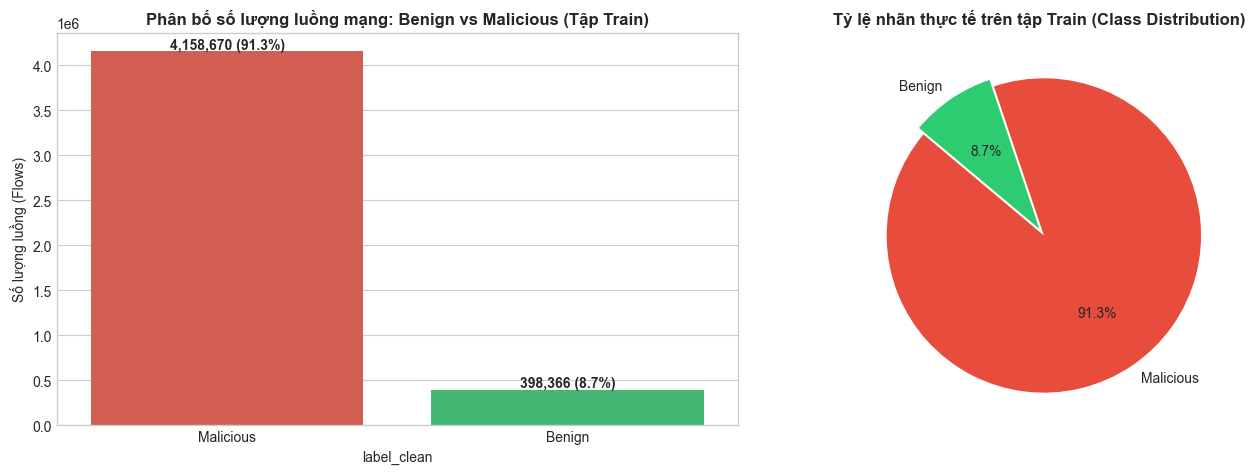

In [3]:
# 3. EDA - PHÂN BỐ LƯỢNG LUỒNG MẠNG (BENIGN VS MALICIOUS)
counts = train_df["label_clean"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#e74c3c", "#2ecc71"], legend=False, ax=ax[0])
ax[0].set_title("Phân bố số lượng luồng mạng: Benign vs Malicious (Tập Train)", fontsize=12, fontweight="bold")
ax[0].set_ylabel("Số lượng luồng (Flows)")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 25000, f"{v:,} ({v/len(train_df)*100:.1f}%)", ha="center", fontweight="bold")

ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=140, colors=["#e74c3c", "#2ecc71"], explode=(0.05, 0))
ax[1].set_title("Tỷ lệ nhãn thực tế trên tập Train (Class Distribution)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

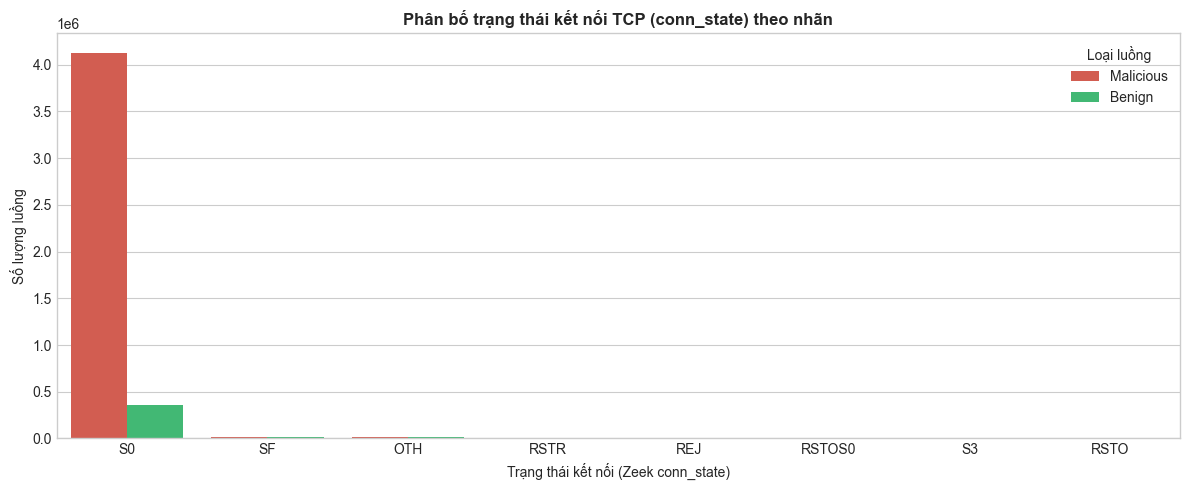

In [4]:
# 4. EDA - PHÂN TÍCH TRẠNG THÁI KẾT NỐI TCP (conn_state)
plt.figure(figsize=(12, 5))
top_conn = train_df["conn_state"].value_counts().head(8).index
sns.countplot(data=train_df[train_df["conn_state"].isin(top_conn)], x="conn_state", hue="label_clean", palette=["#e74c3c", "#2ecc71"])
plt.title("Phân bố trạng thái kết nối TCP (conn_state) theo nhãn", fontsize=12, fontweight="bold")
plt.xlabel("Trạng thái kết nối (Zeek conn_state)")
plt.ylabel("Số lượng luồng")
plt.legend(title="Loại luồng")
plt.tight_layout()
plt.show()

In [5]:
# 5. TIỀN XỬ LÝ VÀ CHUẨN BỊ ĐẶC TRƯNG CHỐNG RÒ RỈ (ANTI-LEAKAGE)
NUMERIC_COLS = ['id.orig_p', 'id.resp_p', 'duration', 'orig_bytes', 'resp_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']
CATEGORICAL_COLS = ['proto', 'conn_state', 'history']

# Xử lý ký tự Zeek thành số
for col in NUMERIC_COLS:
    train_df[col] = pd.to_numeric(train_df[col].replace("-", 0).replace("(empty)", 0), errors="coerce").fillna(0).astype(np.float32)

encoders = {}
for col in CATEGORICAL_COLS:
    le = LabelEncoder()
    train_df[col] = le.fit_transform(train_df[col].astype(str))
    encoders[col] = le

features = NUMERIC_COLS + CATEGORICAL_COLS
X = train_df[features].values
y = train_df["label_clean"].apply(lambda x: 0 if x == "Benign" else 1).values

# Chia tập validation nội bộ để đánh giá
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_val_scaled = scaler.transform(X_val)

print(f"[+] Đặc trưng huấn luyện: {len(features)} đặc trưng!")
print(f"[+] Kích thước X_tr: {X_tr.shape}, X_val: {X_val.shape}")

[+] Đặc trưng huấn luyện: 12 đặc trưng!
[+] Kích thước X_tr: (3873480, 12), X_val: (683556, 12)


In [6]:
# 6. HUẤN LUYỆN VÀ SO SÁNH ĐÁNH GIÁ CÁC MÔ HÌNH MACHINE LEARNING
models = {
    "Logistic Regression": (LogisticRegression(max_iter=200, random_state=42), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=12, random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=25, max_depth=12, n_jobs=-1, random_state=42), False),
    "XGBoost (Hist)": (xgb.XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, eval_metric="logloss", random_state=42, n_jobs=-1, tree_method="hist"), False),
    "LightGBM": (lgb.LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1), False)
}

results = []
print("[*] Đang huấn luyện và so sánh các mô hình trên 4.55 triệu dòng...")

for name, (clf, use_scaled) in models.items():
    X_train_in = X_tr_scaled if use_scaled else X_tr
    X_val_in   = X_val_scaled if use_scaled else X_val
    
    t0 = time.time()
    clf.fit(X_train_in, y_tr)
    t_train = time.time() - t0
    
    y_pred = clf.predict(X_val_in)
    
    results.append({
        "Mô Hình": name,
        "Accuracy": f"{accuracy_score(y_val, y_pred)*100:.2f}%",
        "Precision": f"{precision_score(y_val, y_pred, zero_division=0)*100:.2f}%",
        "Recall (Detection Rate)": f"{recall_score(y_val, y_pred, zero_division=0)*100:.2f}%",
        "F1-Score": f"{f1_score(y_val, y_pred, zero_division=0)*100:.2f}%",
        "Thời gian Train (s)": f"{t_train:.2f}s"
    })

benchmark_df = pd.DataFrame(results)
print("\n=== BẢNG SO SÁNH KẾT QUẢ MÔ HÌNH TRÊN TẬP HUẤN LUYỆN (4,557,036 DÒNG) ===")
display(benchmark_df)

# Lưu mô hình tốt nhất (LightGBM) kèm encoders và scaler ra file bundle
best_clf = models["LightGBM"][0]
save_bundle = {
    "model": best_clf,
    "encoders": encoders,
    "scaler": scaler,
    "features": features,
    "numeric_cols": NUMERIC_COLS,
    "categorical_cols": CATEGORICAL_COLS
}
joblib.dump(save_bundle, "iot_nids_bundle.joblib")
print("\n[+] ĐÃ LƯU BUNDLE MODEL VÀ BỘ MÃ HÓA THÀNH CÔNG TẠI: iot_nids_bundle.joblib!")

[*] Đang huấn luyện và so sánh các mô hình trên 4.55 triệu dòng...


C:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== BẢNG SO SÁNH KẾT QUẢ MÔ HÌNH TRÊN TẬP HUẤN LUYỆN (4,557,036 DÒNG) ===


,Mô Hình,Accuracy,Precision,Recall (Detection Rate),F1-Score,Thời gian Train (s)
0,Logistic Regression,98.32%,98.82%,99.34%,99.08%,28.67s
1,Decision Tree,99.99%,99.99%,100.00%,100.00%,55.12s
2,Random Forest,99.90%,99.89%,100.00%,99.95%,71.61s
3,XGBoost (Hist),99.90%,99.90%,100.00%,99.95%,31.46s
4,LightGBM,99.99%,99.99%,100.00%,99.99%,19.83s



[+] ĐÃ LƯU BUNDLE MODEL VÀ BỘ MÃ HÓA THÀNH CÔNG TẠI: iot_nids_bundle.joblib!
